# Data Cleaning and Preprocessing

## Objective

This notebook prepares the engineered soccer dataset for machine learning.

Main steps:

1. Separate the target and valid candidate features.
2. Remove columns that should not be used for prediction.
3. Check remaining data quality issues.
4. Separate numerical and categorical features.
5. Split the data chronologically.
6. Fit preprocessing steps using training data only.
7. Prepare clean datasets for feature selection and modelling.

In [149]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [150]:
df = pd.read_csv(
    "../data/processed/model_data_engineered.csv"
)

df.shape

(17609, 156)

In [151]:
df["date"] = pd.to_datetime(df["date"])
df["date"].min(), df["date"].max()

(Timestamp('2010-07-17 00:00:00'), Timestamp('2016-05-25 00:00:00'))

In [152]:
identifier_columns = [
    "id",
    "match_api_id",
    "country_id",
    "league_id",
    "home_team_api_id",
    "away_team_api_id"
]

In [153]:
leakage_columns = [
    "home_team_goal",
    "away_team_goal"
]

In [154]:
metadata_columns = [
    "date",
    "country_name",
    "home_team_name",
    "away_team_name"
]

In [155]:
player_id_columns = [
    "home_player_1",
    "home_player_2",
    "home_player_3",
    "home_player_4",
    "home_player_5",
    "home_player_6",
    "home_player_7",
    "home_player_8",
    "home_player_9",
    "home_player_10",
    "home_player_11",
    "away_player_1",
    "away_player_2",
    "away_player_3",
    "away_player_4",
    "away_player_5",
    "away_player_6",
    "away_player_7",
    "away_player_8",
    "away_player_9",
    "away_player_10",
    "away_player_11"
]

In [156]:
position_columns = [
    col for col in df.columns
    if "player_X" in col or "player_Y" in col
]
position_columns

['home_player_X1',
 'home_player_X2',
 'home_player_X3',
 'home_player_X4',
 'home_player_X5',
 'home_player_X6',
 'home_player_X7',
 'home_player_X8',
 'home_player_X9',
 'home_player_X10',
 'home_player_X11',
 'away_player_X1',
 'away_player_X2',
 'away_player_X3',
 'away_player_X4',
 'away_player_X5',
 'away_player_X6',
 'away_player_X7',
 'away_player_X8',
 'away_player_X9',
 'away_player_X10',
 'away_player_X11',
 'home_player_Y1',
 'home_player_Y2',
 'home_player_Y3',
 'home_player_Y4',
 'home_player_Y5',
 'home_player_Y6',
 'home_player_Y7',
 'home_player_Y8',
 'home_player_Y9',
 'home_player_Y10',
 'home_player_Y11',
 'away_player_Y1',
 'away_player_Y2',
 'away_player_Y3',
 'away_player_Y4',
 'away_player_Y5',
 'away_player_Y6',
 'away_player_Y7',
 'away_player_Y8',
 'away_player_Y9',
 'away_player_Y10',
 'away_player_Y11']

In [157]:
attribute_date_columns = [
    "home_team_attr_date",
    "away_team_attr_date"
]

In [158]:
columns_to_remove = (
    identifier_columns
    + leakage_columns
    + metadata_columns
    + player_id_columns
    + position_columns
    + attribute_date_columns
)

In [159]:
X = df.drop(
    columns=columns_to_remove + ["target"]
)

In [160]:
y = df["target"]

In [161]:
X.shape

(17609, 75)

In [162]:
y.shape

(17609,)

In [163]:
X.columns.tolist()

['season',
 'stage',
 'league_name',
 'home_buildUpPlaySpeed',
 'home_buildUpPlayPassing',
 'home_buildUpPlayDribblingClass',
 'home_buildUpPlayPositioningClass',
 'home_chanceCreationPassing',
 'home_chanceCreationCrossing',
 'home_chanceCreationShooting',
 'home_chanceCreationPositioningClass',
 'home_defencePressure',
 'home_defenceAggression',
 'home_defenceTeamWidth',
 'home_defenceDefenderLineClass',
 'away_buildUpPlaySpeed',
 'away_buildUpPlayPassing',
 'away_buildUpPlayDribblingClass',
 'away_buildUpPlayPositioningClass',
 'away_chanceCreationPassing',
 'away_chanceCreationCrossing',
 'away_chanceCreationShooting',
 'away_chanceCreationPositioningClass',
 'away_defencePressure',
 'away_defenceAggression',
 'away_defenceTeamWidth',
 'away_defenceDefenderLineClass',
 'home_form_points_5',
 'home_avg_goals_scored_5',
 'home_avg_goals_conceded_5',
 'away_form_points_5',
 'away_avg_goals_scored_5',
 'away_avg_goals_conceded_5',
 'away_players_listed',
 'home_players_listed',
 'away_

In [164]:
X.isnull().sum().sum()

np.int64(0)

In [165]:
df["id"].duplicated().sum()

np.int64(0)

In [166]:
numeric_X = X.select_dtypes(include="number")

np.isinf(numeric_X).sum().sum()

np.int64(0)

In [167]:
categorical_features = X.select_dtypes(
    include="object"
).columns.tolist()

numerical_features = X.select_dtypes(
    include="number"
).columns.tolist()

/var/folders/_6/kwx5pdg56rq735gq7lswf8hm0000gn/T/ipykernel_54108/2378507109.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [168]:
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

Categorical features: 10
Numerical features: 65


In [169]:
for column in categorical_features:
    print(column)
    print(X[column].value_counts())
    print()

season
season
2015/2016    3129
2014/2015    3067
2012/2013    2944
2011/2012    2864
2013/2014    2808
2010/2011    2797
Name: count, dtype: int64

league_name
league_name
Spain LIGA BBVA             2230
England Premier League      2225
France Ligue 1              2224
Italy Serie A               2213
Germany 1. Bundesliga       1792
Netherlands Eredivisie      1641
Portugal Liga ZON Sagres    1246
Scotland Premier League     1194
Belgium Jupiler League      1029
Switzerland Super League     954
Poland Ekstraklasa           861
Name: count, dtype: int64

home_buildUpPlayDribblingClass
home_buildUpPlayDribblingClass
Little    12246
Normal     5035
Lots        328
Name: count, dtype: int64

home_buildUpPlayPositioningClass
home_buildUpPlayPositioningClass
Organised    16554
Free Form     1055
Name: count, dtype: int64

home_chanceCreationPositioningClass
home_chanceCreationPositioningClass
Organised    15456
Free Form     2153
Name: count, dtype: int64

home_defenceDefenderLineClass
ho

In [170]:
X[numerical_features].describe()

,stage,home_buildUpPlaySpeed,home_buildUpPlayPassing,home_chanceCreationPassing,home_chanceCreationCrossing,home_chanceCreationShooting,home_defencePressure,home_defenceAggression,home_defenceTeamWidth,away_buildUpPlaySpeed,...,recent_goals_scored_diff,recent_goals_conceded_diff,buildUpPlaySpeed_diff,buildUpPlayPassing_diff,chanceCreationPassing_diff,chanceCreationCrossing_diff,chanceCreationShooting_diff,defencePressure_diff,defenceAggression_diff,defenceTeamWidth_diff
count,17609.000000,17609.000000,17609.000000,17609.000000,17609.000000,17609.000000,17609.000000,17609.000000,17609.000000,17609.000000,...,17609.000000,17609.000000,17609.000000,17609.000000,17609.000000,17609.000000,17609.000000,17609.000000,17609.000000,17609.000000
mean,18.750298,52.745130,48.036970,52.578795,54.278778,53.652621,46.180589,49.240786,52.265319,52.740246,...,-0.038367,0.037810,0.004884,0.016526,0.036459,0.020898,0.002839,0.058720,0.024930,0.010392
std,10.355151,11.547976,10.849239,10.247430,10.943435,10.348917,9.742207,9.216245,8.953926,11.537811,...,0.906669,0.817296,14.834659,14.340314,13.803780,14.873975,13.516531,12.743942,11.622205,11.423329
min,1.000000,20.000000,20.000000,21.000000,20.000000,22.000000,23.000000,24.000000,30.000000,20.000000,...,-5.000000,-3.600000,-50.000000,-51.000000,-47.000000,-54.000000,-57.000000,-45.000000,-46.000000,-41.000000
25%,10.000000,46.000000,40.000000,47.000000,48.000000,48.000000,39.000000,44.000000,48.000000,46.000000,...,-0.600000,-0.400000,-10.000000,-9.000000,-9.000000,-10.000000,-9.000000,-9.000000,-8.000000,-6.000000
50%,19.000000,53.000000,49.000000,52.000000,54.000000,53.000000,46.000000,48.000000,52.000000,53.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,27.000000,62.000000,55.000000,60.000000,63.000000,61.000000,52.000000,55.000000,58.000000,62.000000,...,0.600000,0.600000,10.000000,10.000000,9.000000,10.000000,9.000000,9.000000,8.000000,6.000000
max,38.000000,80.000000,80.000000,80.000000,80.000000,80.000000,72.000000,72.000000,73.000000,80.000000,...,5.200000,3.400000,50.000000,51.000000,47.000000,54.000000,57.000000,41.000000,46.000000,41.000000


In [171]:
X.isnull().sum().sum()

np.int64(0)

In [172]:
np.isinf(
    X[numerical_features]
).sum().sum()

np.int64(0)

In [173]:
constant_features = [
    column for column in X.columns
    if X[column].nunique() == 1
]

constant_features

[]

In [174]:
for column in categorical_features:
    print(
        column,
        X[column].nunique()
    )

season 6
league_name 11
home_buildUpPlayDribblingClass 3
home_buildUpPlayPositioningClass 2
home_chanceCreationPositioningClass 2
home_defenceDefenderLineClass 2
away_buildUpPlayDribblingClass 3
away_buildUpPlayPositioningClass 2
away_chanceCreationPositioningClass 2
away_defenceDefenderLineClass 2


### Chronological train / validation / test split

In [175]:
df["season"].value_counts().sort_index()

season
2010/2011    2797
2011/2012    2864
2012/2013    2944
2013/2014    2808
2014/2015    3067
2015/2016    3129
Name: count, dtype: int64

In [176]:
train_df = df[
    df["season"].isin([
        "2010/2011",
        "2011/2012",
        "2012/2013",
        "2013/2014"
    ])
]

val_df = df[
    df["season"] == "2014/2015"
]

test_df = df[
    df["season"] == "2015/2016"
]

In [177]:
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (11413, 156)
Validation: (3067, 156)
Test: (3129, 156)


In [178]:
print(
    "Train:",
    train_df["date"].min(),
    "to",
    train_df["date"].max()
)

print(
    "Validation:",
    val_df["date"].min(),
    "to",
    val_df["date"].max()
)

print(
    "Test:",
    test_df["date"].min(),
    "to",
    test_df["date"].max()
)

Train: 2010-07-17 00:00:00 to 2014-05-18 00:00:00
Validation: 2014-07-18 00:00:00 to 2015-05-31 00:00:00
Test: 2015-07-17 00:00:00 to 2016-05-25 00:00:00


In [179]:
print("TRAIN")
print(
    train_df["target"].value_counts(normalize=True)
)

print("\nVALIDATION")
print(
    val_df["target"].value_counts(normalize=True)
)

print("\nTEST")
print(
    test_df["target"].value_counts(normalize=True)
)

TRAIN
target
Home Win    0.462105
Away Win    0.286603
Draw        0.251292
Name: proportion, dtype: float64

VALIDATION
target
Home Win    0.447995
Away Win    0.295403
Draw        0.256603
Name: proportion, dtype: float64

TEST
target
Home Win    0.440396
Away Win    0.303611
Draw        0.255992
Name: proportion, dtype: float64


In [180]:
feature_columns = X.columns.tolist()

In [181]:
X_train = train_df[feature_columns]
y_train = train_df["target"]

X_val = val_df[feature_columns]
y_val = val_df["target"]

X_test = test_df[feature_columns]
y_test = test_df["target"]

In [182]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (11413, 75)
X_val: (3067, 75)
X_test: (3129, 75)


In [183]:
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

y_train: (11413,)
y_val: (3067,)
y_test: (3129,)


In [184]:
print(
    "Train & Validation overlap:",
    set(train_df["id"]) &
    set(val_df["id"])
)

print(
    "Train & Test overlap:",
    set(train_df["id"]) &
    set(test_df["id"])
)

print(
    "Validation & Test overlap:",
    set(val_df["id"]) &
    set(test_df["id"])
)

Train & Validation overlap: set()
Train & Test overlap: set()
Validation & Test overlap: set()


In [185]:
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

X_train["season_start_year"] = X_train["season"].str[:4].astype(int)
X_val["season_start_year"] = X_val["season"].str[:4].astype(int)
X_test["season_start_year"] = X_test["season"].str[:4].astype(int)

In [186]:
X_train = X_train.drop(columns=["season"])
X_val = X_val.drop(columns=["season"])
X_test = X_test.drop(columns=["season"])

In [187]:
categorical_features = X_train.select_dtypes(
    include="object"
).columns.tolist()

categorical_features

/var/folders/_6/kwx5pdg56rq735gq7lswf8hm0000gn/T/ipykernel_54108/3302999233.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


['league_name',
 'home_buildUpPlayDribblingClass',
 'home_buildUpPlayPositioningClass',
 'home_chanceCreationPositioningClass',
 'home_defenceDefenderLineClass',
 'away_buildUpPlayDribblingClass',
 'away_buildUpPlayPositioningClass',
 'away_chanceCreationPositioningClass',
 'away_defenceDefenderLineClass']

In [188]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    drop="first",
    sparse_output=False
)


encoder.fit(
    X_train[categorical_features]
)

,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",'first'
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infre

In [189]:
train_encoded = encoder.transform(
    X_train[categorical_features]
)

val_encoded = encoder.transform(
    X_val[categorical_features]
)

test_encoded = encoder.transform(
    X_test[categorical_features]
)

/Users/sasanda/Documents/insuarance claim prediction/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/Users/sasanda/Documents/insuarance claim prediction/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [190]:
encoded_columns = encoder.get_feature_names_out(
    categorical_features
)

In [191]:
train_encoded = pd.DataFrame(
    train_encoded,
    columns=encoded_columns,
    index=X_train.index
)

val_encoded = pd.DataFrame(
    val_encoded,
    columns=encoded_columns,
    index=X_val.index
)

test_encoded = pd.DataFrame(
    test_encoded,
    columns=encoded_columns,
    index=X_test.index
)

In [192]:
X_train_processed = X_train.drop(
    columns=categorical_features
)

X_val_processed = X_val.drop(
    columns=categorical_features
)

X_test_processed = X_test.drop(
    columns=categorical_features
)

In [193]:
X_train_processed = pd.concat(
    [X_train_processed, train_encoded],
    axis=1
)

X_val_processed = pd.concat(
    [X_val_processed, val_encoded],
    axis=1
)

X_test_processed = pd.concat(
    [X_test_processed, test_encoded],
    axis=1
)

In [194]:
print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

Train: (11413, 82)
Validation: (3067, 82)
Test: (3129, 82)


In [195]:
X_train_processed.head()

,stage,home_buildUpPlaySpeed,home_buildUpPlayPassing,home_chanceCreationPassing,home_chanceCreationCrossing,home_chanceCreationShooting,home_defencePressure,home_defenceAggression,home_defenceTeamWidth,away_buildUpPlaySpeed,...,league_name_Portugal Liga ZON Sagres,league_name_Scotland Premier League,league_name_Spain LIGA BBVA,league_name_Switzerland Super League,home_buildUpPlayPositioningClass_Organised,home_chanceCreationPositioningClass_Organised,home_defenceDefenderLineClass_Offside Trap,away_buildUpPlayPositioningClass_Organised,away_chanceCreationPositioningClass_Organised,away_defenceDefenderLineClass_Offside Trap
0,1,30.0,50.0,55.0,70.0,55.0,40.0,60.0,60.0,60.0,...,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0
1,1,40.0,50.0,55.0,65.0,55.0,45.0,50.0,55.0,35.0,...,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0
2,1,45.0,60.0,45.0,70.0,60.0,40.0,45.0,50.0,35.0,...,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
3,1,40.0,45.0,50.0,65.0,50.0,60.0,60.0,60.0,45.0,...,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0
4,2,35.0,60.0,50.0,60.0,60.0,35.0,40.0,45.0,40.0,...,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0


In [196]:
X_train_processed.select_dtypes(
    include="object"
).columns


Index([], dtype='str')

In [197]:
print(
    "Train missing:",
    X_train_processed.isnull().sum().sum()
)

print(
    "Validation missing:",
    X_val_processed.isnull().sum().sum()
)

print(
    "Test missing:",
    X_test_processed.isnull().sum().sum()
)

Train missing: 0
Validation missing: 0
Test missing: 0


In [198]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    drop="first",
    sparse_output=False
)

### Feature selection

In [199]:
from sklearn.feature_selection import VarianceThreshold

In [200]:
selector = VarianceThreshold(threshold=0)

selector.fit(X_train_processed)

VarianceThreshold(threshold=0)

In [201]:
low_variance_features = X_train_processed.columns[
    ~selector.get_support()
]

low_variance_features

Index([], dtype='str')

In [218]:
correlation_matrix = X_train_processed.corr().abs()

In [203]:
correlation_matrix.head()

,stage,home_buildUpPlaySpeed,home_buildUpPlayPassing,home_chanceCreationPassing,home_chanceCreationCrossing,home_chanceCreationShooting,home_defencePressure,home_defenceAggression,home_defenceTeamWidth,away_buildUpPlaySpeed,...,league_name_Portugal Liga ZON Sagres,league_name_Scotland Premier League,league_name_Spain LIGA BBVA,league_name_Switzerland Super League,home_buildUpPlayPositioningClass_Organised,home_chanceCreationPositioningClass_Organised,home_defenceDefenderLineClass_Offside Trap,away_buildUpPlayPositioningClass_Organised,away_chanceCreationPositioningClass_Organised,away_defenceDefenderLineClass_Offside Trap
stage,1.000000,0.008887,0.025643,0.006496,0.013149,0.083167,0.045447,0.027968,0.002573,0.001148,...,0.077430,0.030528,0.040850,0.002028,0.039200,0.010626,0.098137,0.038928,0.008669,0.097033
home_buildUpPlaySpeed,0.008887,1.000000,0.426175,0.293090,0.164704,0.144173,0.067404,0.162023,0.038668,0.205373,...,0.153772,0.122033,0.172415,0.015099,0.029231,0.004345,0.038834,0.001586,0.028383,0.029327
home_buildUpPlayPassing,0.025643,0.426175,1.000000,0.109334,0.187683,0.081183,0.115355,0.135915,0.003666,0.139781,...,0.126523,0.192821,0.099280,0.047828,0.201697,0.212928,0.206641,0.062483,0.027395,0.107989
home_chanceCreationPassing,0.006496,0.293090,0.109334,1.000000,0.158894,0.168498,0.211604,0.159985,0.111620,0.052554,...,0.064211,0.029854,0.112124,0.018387,0.056215,0.076996,0.030374,0.015558,0.018781,0.038626
home_chanceCreationCrossing,0.013149,0.164704,0.187683,0.158894,1.000000,0.035639,0.063040,0.144643,0.086823,0.059630,...,0.040158,0.014241,0.039099,0.032538,0.064013,0.077524,0.001224,0.001210,0.035061,0.023940


In [204]:
high_corr_pairs = []

columns = correlation_matrix.columns

for i in range(len(columns)):
    for j in range(i):
        correlation = correlation_matrix.iloc[i, j]

        if correlation > 0.95:
            high_corr_pairs.append([
                columns[i],
                columns[j],
                correlation
            ])

In [205]:
high_corr_df = pd.DataFrame(
    high_corr_pairs,
    columns=[
        "feature_1",
        "feature_2",
        "correlation"
    ]
)

high_corr_df

,feature_1,feature_2,correlation
0,away_players_with_attributes,away_players_listed,0.971810
1,home_players_with_attributes,home_players_listed,0.967818
2,away_avg_potential,away_avg_overall_rating,0.952421
3,home_avg_potential,home_avg_overall_rating,0.953087


In [206]:
high_corr_df.sort_values(
    "correlation",
    ascending=False
)

,feature_1,feature_2,correlation
0,away_players_with_attributes,away_players_listed,0.971810
1,home_players_with_attributes,home_players_listed,0.967818
3,home_avg_potential,home_avg_overall_rating,0.953087
2,away_avg_potential,away_avg_overall_rating,0.952421


In [207]:
high_corr_df.to_csv(
    "../outputs/tables/highly_correlated_features.csv",
    index=False
)

In [208]:
train_analysis = X_train_processed.copy()

train_analysis["target"] = y_train

In [209]:
difference_features = [
    "overall_rating_diff",
    "attack_diff",
    "passing_diff",
    "pace_diff",
    "defence_diff",
    "form_points_diff",
    "recent_goals_scored_diff",
    "recent_goals_conceded_diff"
]

In [210]:
difference_features = [
    col for col in difference_features
    if col in train_analysis.columns
]

In [211]:
train_analysis.groupby(
    "target"
)[difference_features].mean()

,overall_rating_diff,attack_diff,passing_diff,pace_diff,defence_diff,form_points_diff,recent_goals_scored_diff,recent_goals_conceded_diff
target,,,,,,,,
Away Win,-2.479094,-2.438663,-2.754932,-1.779209,-1.696399,-1.642311,-0.306267,0.217242
Draw,-0.400831,-0.381745,-0.488643,-0.189627,-0.615586,-0.626918,-0.099861,0.094630
Home Win,1.895644,2.166902,2.050517,1.451157,0.648395,0.760903,0.156883,-0.091468


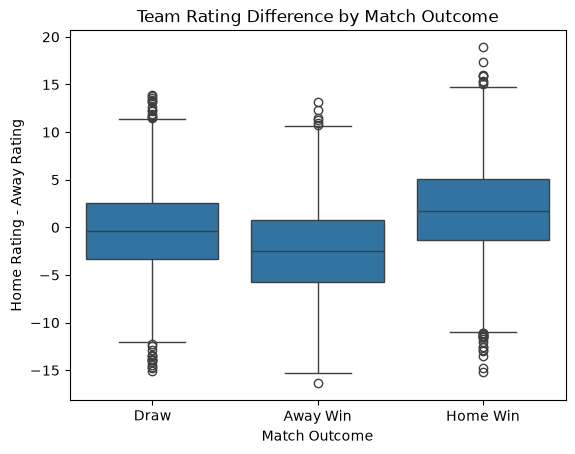

In [212]:
sns.boxplot(
    data=train_analysis,
    x="target",
    y="overall_rating_diff"
)

plt.title(
    "Team Rating Difference by Match Outcome"
)

plt.xlabel("Match Outcome")
plt.ylabel("Home Rating - Away Rating")

plt.show()

In [213]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(
    y_train
)

In [214]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(
    X_train_processed,
    y_train_encoded,
    random_state=42
)
mi_results = pd.DataFrame({
    "feature": X_train_processed.columns,
    "mutual_information": mi_scores
})
mi_results = mi_results.sort_values(
    "mutual_information",
    ascending=False
)

mi_results.head(20)
mi_results.to_csv(
    "../outputs/tables/mutual_information_scores.csv",
    index=False
)

In [215]:
top_20 = mi_results.head(20)

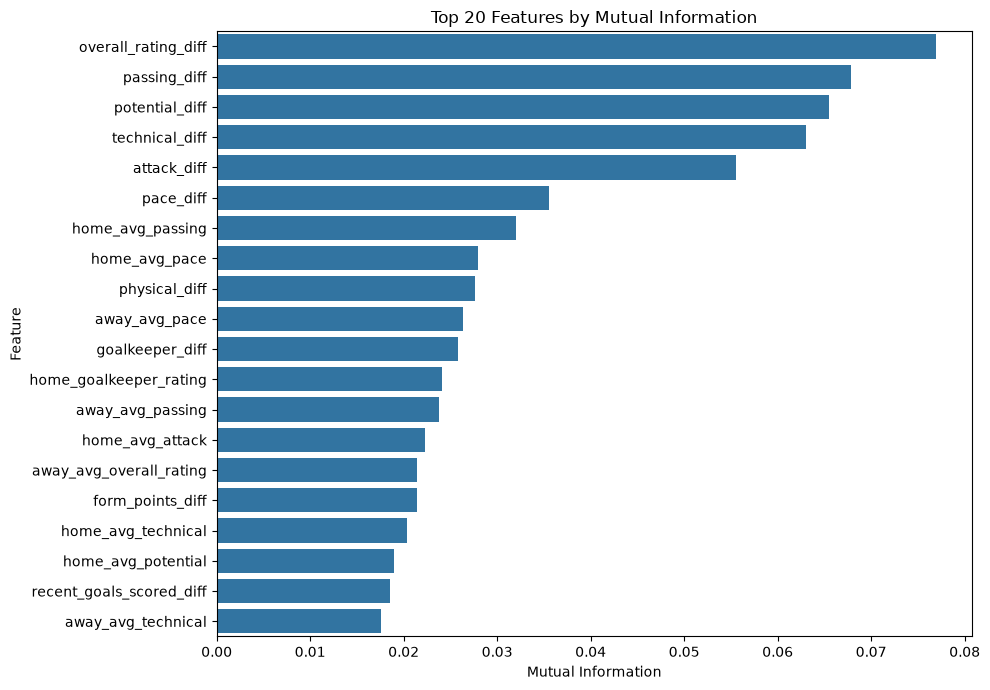

In [216]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_20,
    x="mutual_information",
    y="feature"
)

plt.title(
    "Top 20 Features by Mutual Information"
)

plt.xlabel("Mutual Information")
plt.ylabel("Feature")

plt.tight_layout()


plt.show()

In [ ]:
constant_features = [
    "home_buildUpPlayDribblingClass_Little",
    "away_buildUpPlayDribblingClass_Little"
]

X_train_processed = X_train_processed.drop(
    columns=constant_features
)

X_val_processed = X_val_processed.drop(
    columns=constant_features
)

X_test_processed = X_test_processed.drop(
    columns=constant_features
)

In [222]:
redundant_features = [
    "home_players_listed",
    "away_players_listed"
]

X_train_processed = X_train_processed.drop(
    columns=redundant_features
)

X_val_processed = X_val_processed.drop(
    columns=redundant_features
)

X_test_processed = X_test_processed.drop(
    columns=redundant_features
)

In [223]:
print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

Train: (11413, 80)
Validation: (3067, 80)
Test: (3129, 80)


In [224]:
train_ready = X_train_processed.copy()
train_ready["target"] = y_train

val_ready = X_val_processed.copy()
val_ready["target"] = y_val

test_ready = X_test_processed.copy()
test_ready["target"] = y_test

In [225]:
train_ready.to_csv(
    "../data/processed/train_processed.csv",
    index=False
)

val_ready.to_csv(
    "../data/processed/validation_processed.csv",
    index=False
)

test_ready.to_csv(
    "../data/processed/test_processed.csv",
    index=False
)

In [226]:
print(train_ready.shape)
print(val_ready.shape)
print(test_ready.shape)

(11413, 81)
(3067, 81)
(3129, 81)


In [227]:
train_df = pd.read_csv(
    "../data/processed/train_processed.csv"
)

val_df = pd.read_csv(
    "../data/processed/validation_processed.csv"
)

test_df = pd.read_csv(
    "../data/processed/test_processed.csv"
)

In [228]:
X_train = train_df.drop(columns=["target"])
y_train = train_df["target"]

X_val = val_df.drop(columns=["target"])
y_val = val_df["target"]

X_test = test_df.drop(columns=["target"])
y_test = test_df["target"]

In [229]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (11413, 80)
Validation: (3067, 80)
Test: (3129, 80)


Dummy Accuracy: 0.44799478317574176
Dummy Macro F1: 0.20625985138482325


In [234]:
rf_accuracy = accuracy_score(
    y_val,
    rf_predictions
)

rf_f1 = f1_score(
    y_val,
    rf_predictions,
    average="macro"
)

print("Random Forest Accuracy:", rf_accuracy)
print("Random Forest Macro F1:", rf_f1)

Random Forest Accuracy: 0.5112487773068145
Random Forest Macro F1: 0.38887939643726943


In [235]:
from sklearn.metrics import classification_report
print(
    classification_report(
        y_val,
        rf_predictions
    )
)

              precision    recall  f1-score   support

    Away Win       0.51      0.46      0.48       906
        Draw       0.26      0.03      0.05       787
    Home Win       0.52      0.82      0.64      1374

    accuracy                           0.51      3067
   macro avg       0.43      0.44      0.39      3067
weighted avg       0.45      0.51      0.44      3067



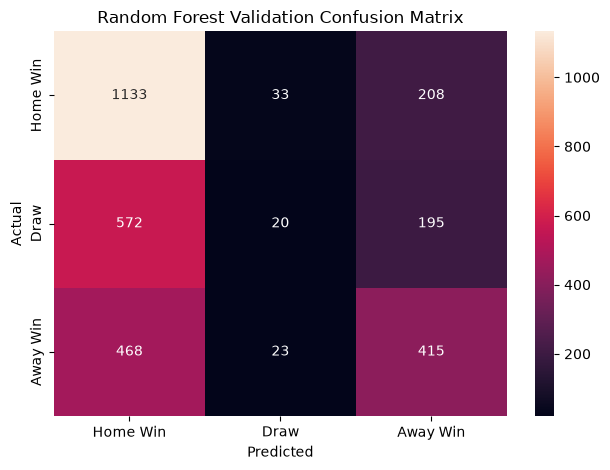

<Figure size 640x480 with 0 Axes>

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_val,
    rf_predictions,
    labels=[
        "Home Win",
        "Draw",
        "Away Win"
    ]
)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Home Win",
        "Draw",
        "Away Win"
    ],
    yticklabels=[
        "Home Win",
        "Draw",
        "Away Win"
    ]
)

plt.title("Random Forest Validation Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [238]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

feature_importance.head(20)

,feature,importance
43,overall_rating_diff,0.032009
44,potential_diff,0.029574
46,passing_diff,0.028607
47,technical_diff,0.028521
45,attack_diff,0.023615
48,pace_diff,0.021273
49,physical_diff,0.020711
36,home_avg_technical,0.019264
50,defence_diff,0.019118
51,goalkeeper_diff,0.018922


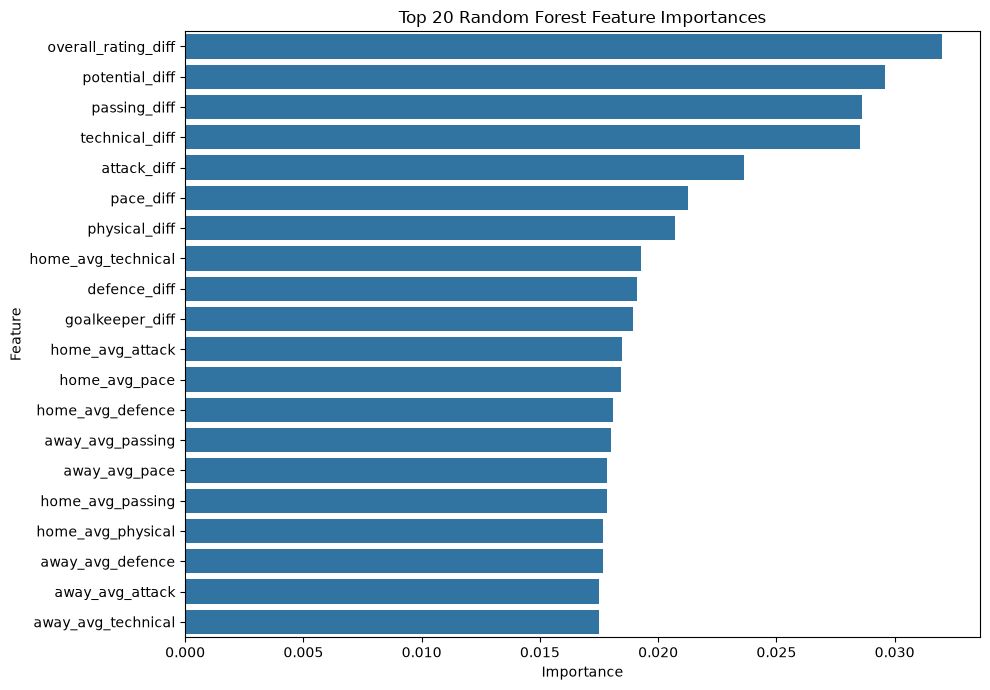

In [ ]:
top_rf_features = feature_importance.head(20)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_rf_features,
    x="importance",
    y="feature"
)

plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()


plt.show()

In [240]:
feature_importance.to_csv(
    "../outputs/tables/random_forest_feature_importance.csv",
    index=False
)